In [ ]:
# === SETUP ===
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from scipy.optimize import minimize
from scipy.stats import rankdata
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, CatBoostRegressor
from sklearn.linear_model import RidgeClassifier, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from scipy.special import expit
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from pytabkit import TabM_D_Classifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import TargetEncoder
from tqdm import tqdm
from realmlp import RealMLP_TD_Classifier, seed_everything
from utils import *
import warnings
import copy
import time
import gc
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
torch.cuda.set_per_process_memory_fraction(0.70, device=0)
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (14, 6), 'font.size': 11, 'figure.dpi': 100})

print('Setup complete!')

In [2]:
train = pd.read_csv('dataset/train.csv')
test = pd.read_csv('dataset/test.csv')
original = pd.read_csv('dataset/data.csv')

In [ ]:
def preprocess_data(df, arrival_delay_median=None):
    """Engineer EDA-informed, numeric features from the raw passenger data."""
    rating_cols = [
        'Inflight wifi service', 'Departure/Arrival time convenient',
        'Ease of Online booking', 'Gate location', 'Food and drink',
        'Online boarding', 'Seat comfort', 'Inflight entertainment',
        'On-board service', 'Leg room service', 'Baggage handling',
        'Checkin service', 'Cleanliness',
    ]

    arrival_col = 'Arrival Delay in Minutes'
    if arrival_delay_median is None:
        arrival_delay_median = df[arrival_col].median()
    if pd.isna(arrival_delay_median) or not np.isfinite(arrival_delay_median):
        raise ValueError('A finite arrival-delay median is required for imputation.')

    out = df[[
        'Age', 'Flight Distance', *rating_cols,
        'Departure Delay in Minutes', arrival_col,
    ]].copy()
    # out['arrival_delay_missing'] = out[arrival_col].isna().astype('int8')
    out[arrival_col] = out[arrival_col].fillna(float(arrival_delay_median))

    ratings = df[rating_cols]
    rated = ratings.where(ratings > 0)
    rated_count = rated.count(axis=1)
    out['rating_mean'] = rated.sum(axis=1) / rated_count.clip(lower=1)
    out['rating_count'] = rated_count.astype('int8')
    out['rating_unrated_count'] = ratings.eq(0).sum(axis=1).astype('int8')
    out['rating_high_count'] = ratings.ge(4).sum(axis=1).astype('int8')
    out['rating_low_count'] = (ratings.gt(0) & ratings.le(2)).sum(axis=1).astype('int8')

    rating_groups = {
        'digital': ['Inflight wifi service', 'Ease of Online booking', 'Online boarding'],
        'comfort': ['Food and drink', 'Seat comfort', 'Inflight entertainment', 'Leg room service', 'Cleanliness'],
        'onboard': ['On-board service', 'Baggage handling', 'Checkin service'],
        'airport': ['Departure/Arrival time convenient', 'Gate location'],
    }
    for group, columns in rating_groups.items():
        values = ratings[columns].where(ratings[columns] > 0)
        out[f'{group}_rating_mean'] = values.sum(axis=1) / values.count(axis=1).clip(lower=1)

    boarding_high = df['Online boarding'].ge(4)
    business_class = df['Class'].eq('Business')
    business_travel = df['Type of Travel'].eq('Business travel')
    out['age_band'] = pd.cut(df['Age'], [-np.inf, 18, 30, 45, 60, np.inf], labels=False).astype('category')
    out['log_flight_distance'] = np.log1p(out['Flight Distance'])
    out['total_delay_minutes'] = out['Departure Delay in Minutes'] + out[arrival_col]
    out['log_total_delay'] = np.log1p(out['total_delay_minutes'])
    out['delay_difference'] = out[arrival_col] - out['Departure Delay in Minutes']
    out['any_delay'] = out['total_delay_minutes'].gt(0).astype('int8')
    out['boarding_high'] = boarding_high.astype('int8')
    out['boarding_unrated'] = df['Online boarding'].eq(0).astype('int8')
    # out['boarding_unrated_business_class'] = (df['Online boarding'].eq(0) & business_class).astype('int8')
    out['business_class_business_travel'] = (business_class & business_travel).astype('int8')
    out['personal_travel_economy_class'] = (
        df['Type of Travel'].eq('Personal Travel') & df['Class'].isin(['Eco', 'Eco Plus'])
    ).astype('int8')
    out['boarding_high_business_class'] = (boarding_high & business_class).astype('int8')
    out['boarding_high_business_travel'] = (boarding_high & business_travel).astype('int8')
    out['boarding_high_loyal_customer'] = (
        boarding_high & df['Customer Type'].eq('Loyal Customer')
    ).astype('int8')
    out['log_distance_x_boarding_high'] = out['log_flight_distance'] * boarding_high.astype('int8')

    categories = {
        # 'Gender': ['Female', 'Male'],
        'Customer Type': ['Loyal Customer', 'disloyal Customer'],
        'Type of Travel': ['Business travel', 'Personal Travel'],
        'Class': ['Business', 'Eco', 'Eco Plus'],
    }
    # encoded = []
    # for column, known_values in categories.items():
    #     values = df[column].astype('string').fillna('Other')
    #     values = values.where(values.isin(known_values), 'Other')
        # categorical = pd.Series(
        #     pd.Categorical(values, categories=[*known_values, 'Other']),
        #     index=df.index,
        #     name=column,
        # )
        # encoded.append(pd.get_dummies(categorical, prefix=column, dtype='int8'))
    # out = pd.concat([out, *encoded], axis=1)

    out['Gender'] = df['Gender'].apply(lambda x: 1 if x == 'Male' else 0).astype('category')
    out['Customer Type'] = df['Customer Type'].map({'Loyal Customer': 1, 'disloyal Customer': 0}).astype('category')
    out['Type of Travel'] = df['Type of Travel'].map({'Business travel': 1, 'Personal Travel': 0}).astype('category')
    out['Class'] = df['Class'].map({'Business': 2, 'Eco': 0, 'Eco Plus': 1}).astype('category')
    
    if out.isna().any().any():
        raise ValueError('Preprocessing produced missing feature values.')
    return out


# Reuse one imputation value so train, test, and supplemental rows are consistent.
arrival_delay_median = train['Arrival Delay in Minutes'].median()
X_train = preprocess_data(train, arrival_delay_median)
X_test = preprocess_data(test, arrival_delay_median)
X_original = preprocess_data(original, arrival_delay_median)
y_train = train['satisfaction'].astype('int8')
y_original = original['satisfaction'].astype('int8')

if not X_train.columns.equals(X_test.columns) or not X_train.columns.equals(X_original.columns):
    raise RuntimeError('Preprocessed datasets do not have identical feature columns.')

print(f'Train features:    {X_train.shape}')
print(f'Test features:     {X_test.shape}')
print(f'Original features: {X_original.shape}')
print(f'Arrival-delay median used: {arrival_delay_median}')

Train features:    (699635, 45)
Test features:     (299844, 45)
Original features: (129880, 45)
Arrival-delay median used: 0.0


In [18]:
X_train.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,...,business_class_business_travel,personal_travel_economy_class,boarding_high_business_class,boarding_high_business_travel,boarding_high_loyal_customer,log_distance_x_boarding_high,Gender,Customer Type,Type of Travel,Class
0,36,694,4,4,4,3,1,4,1,1,...,0,1,0,0,1,6.543912,0,1,0,0
1,56,651,5,5,5,5,5,4,4,5,...,1,0,1,1,1,6.480045,1,1,1,2
2,31,1371,3,4,2,5,3,3,3,3,...,0,1,0,0,0,0.000000,0,1,0,0
3,10,1616,3,5,3,3,3,3,3,3,...,0,1,0,0,0,0.000000,1,1,0,0
4,23,481,3,4,3,4,5,3,5,5,...,0,0,0,0,0,0.000000,0,0,1,0


In [19]:
# === FINAL, STABLE TRAINING STACK ===

# Remove broken / redundant columns before model fitting.
drop_cols = ['id','satisfaction','target']
FEATURES = [c for c in X_train.columns if c not in drop_cols]
constant_cols = [c for c in FEATURES if X_train[c].nunique() <= 1]
FEATURES = [c for c in FEATURES if c not in constant_cols]

corr = X_train[FEATURES].sample(min(30000, len(X_train)), random_state=42).corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
redundant_cols = [c for c in upper.columns if any(upper[c] > 0.96)]
# FEATURES = [c for c in FEATURES if c not in redundant_cols]
cat_cols = [c for c in FEATURES if str(X_train[c].dtype) == 'category']
TE_COLS = [c for c in FEATURES if c in cat_cols]

print(f'Features kept: {len(FEATURES)}')
print(f'Redundant features: {len(redundant_cols)}')

Features kept: 45
Redundant features: 4


In [20]:
lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'learning_rate': 0.005,
    'num_leaves': 68,
    'max_depth': 9,
    # 'num_leaves': 63,
    # 'max_depth': 7,
    'min_child_samples': 42,
    'subsample': 0.9,
    'colsample_bytree': 0.8,
    'reg_alpha': 0.1,
    'reg_lambda': 2.0,
    # 'scale_pos_weight': 4.7,
    'verbosity': -1,
    'n_estimators': 30000,
    'device': 'gpu' if torch.cuda.is_available() else 'cpu',
}

xgb_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'eta': 0.02,
    'max_depth': 6,
    'min_child_weight': 20,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'gamma': 0.5,
    'alpha': 0.1,
    'lambda': 1.5,
    # 'scale_pos_weight': 4.7,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    # 'tree_method': 'gpu_hist' if torch.cuda.is_available() else 'hist',
    'tree_method': 'hist',
}

cat_params = {
    'loss_function': 'Logloss',
    'eval_metric': 'AUC',
    'learning_rate': 0.03,
    'depth': 9,
    # 'depth': 7,
    'l2_leaf_reg': 3.0,
    'bagging_temperature': 1.0,
    'random_strength': 1.0,
    'min_data_in_leaf': 30,
    'border_count': 128,
    'od_type': 'Iter',
    'od_wait': 300,
    'iterations': 8000,
    'task_type': 'GPU' if torch.cuda.is_available() else 'CPU',
}
tabm_params = {
    "verbosity": 0,
    # "arch_type": "tabm-mini-normal",
    "arch_type": "tabm-normal",
    "num_emb_type": "pwl",
    "tabm_k": 24,
    "d_embedding": 32,
    "dropout": 0.12,
    "batch_size": 512,
    "lr": 1e-3,
    "n_epochs": 100,
    "d_block": 256,
    "n_blocks": 5,
    "patience": 2,
    "weight_decay": 3e-3,
    "device": "cuda",
}
CLASSES = [0,1]
seed_everything(42)

realmlp_params = {
    'n_ens': 8,
    'embed_dim': 7,
    'onehot_thresh': 10,
    'hidden_dims': [512, 512, 512],
    'dropout': 0.044,
    'p_drop_sched': 'expm4t',
    'activation': nn.GELU,
    'add_front_scale': True,
    'pbld_hidden_dim': 16,
    'pbld_out_dim': 5,
    'pbld_freq_scale': 2.33,
    'pbld_activation': nn.PReLU,
    'pbld_lr_factor': 0.115,
    'lr': 0.01,
    'mom': 0.9,
    'sq_mom': 0.98,
    'lr_sched': 'flat_cos',
    'flat_ratio': 0.20,
    'first_layer_lr_factor': 1.0,
    'first_layer_wd_factor': 0.1,
    'lr_scale_mult': 10.0,
    'lr_bias_mult': 0.1,
    'weight_decay': 0.0125,
    'wd_scale_mult': 0.1,
    'wd_bias_mult': 0.5,
    'grad_clip': 1.0,
    'class_weight_power': 0.0,
    'class_weight_multipliers': None,
    'sample_weight_power': 0.0,
    'loss_prior_power': 1.075,
    'focal_gamma': 0.0,
    'eval_class_multipliers': None,
    'ls_eps': 0.04,
    'ls_eps_sched': 'cos',
    'tfms': ['median_center', 'robust_scale'],
    'epochs': 7,
    'train_bs': 256,
    'eval_bs': 10240,
    'numeric_noise_std': 0.0,
    'ema_decay': 0.997875,
    'verbosity': 2,
    'use_early_stopping': False,
    'early_stopping_additive_patience': 10,
    'early_stopping_multiplicative_patience': 1,
    'device': str(torch.device('cuda' if torch.cuda.is_available() else 'cpu')),
    'random_state': 42,
}
lr_params_default = {
    'penalty': 'l2',
    'C': 0.1,
    'solver': 'lbfgs',
    'max_iter': 1000,
    'n_jobs': -1,
    'class_weight': 'balanced',
}
lr_params_elasticnet = {
    'penalty': 'elasticnet',
    'C': 0.05,
    'l1_ratio': 0.5,
    'solver': 'saga',
    'max_iter': 2000,
    'tol': 1e-3,
    'n_jobs': -1,
    'class_weight': 'balanced',
}


# Use a small, robust seed set for variance reduction.
seeds = [42, 101, 2026]

In [21]:
oof_lgbm, test_lgbm, scores_lgbm, fi_lgbm = train_cv_lgbm(
    X_train, y_train, X_test, FEATURES,
    params=lgb_params,
    TE_COLS=TE_COLS,
    n_splits=5,
    seed=42,
    return_feature_importance=True
)

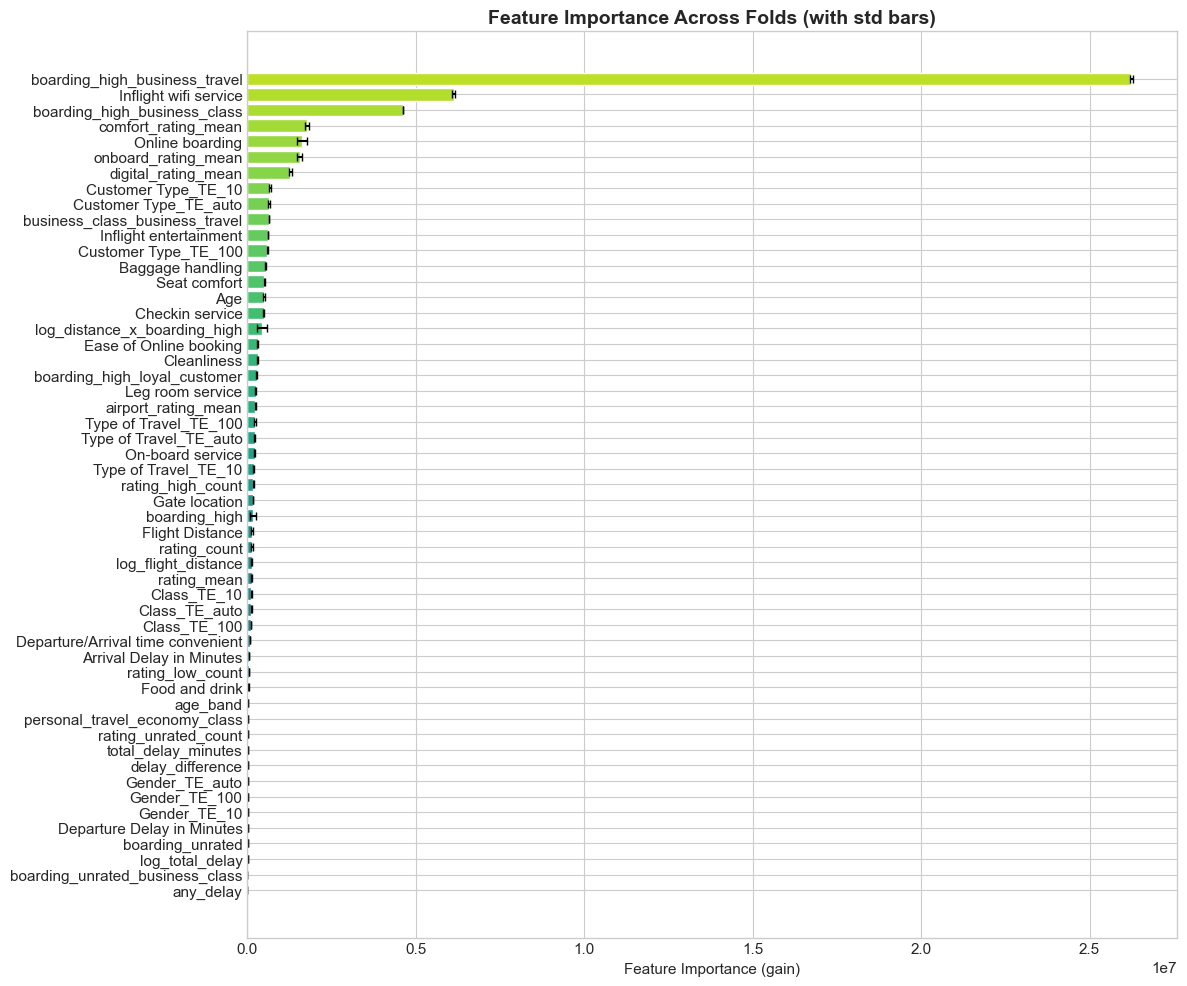


Top 10 features:
  business_class_business_travel      importance =      638,548 +/-    5,555
  Customer Type_TE_auto               importance =      644,091 +/-   31,553
  Customer Type_TE_10                 importance =      669,629 +/-   20,854
  digital_rating_mean                 importance =    1,275,719 +/-   38,424
  onboard_rating_mean                 importance =    1,553,836 +/-   65,858
  Online boarding                     importance =    1,622,010 +/-  157,324
  comfort_rating_mean                 importance =    1,767,937 +/-   64,388
  boarding_high_business_class        importance =    4,617,687 +/-    7,668
  Inflight wifi service               importance =    6,121,900 +/-   44,659
  boarding_high_business_travel       importance =   26,241,395 +/-   38,268


In [23]:
# === ANALYSIS 1: FEATURE IMPORTANCE ===
# This tells you: Which features does the MODEL think are most useful?
# Compare this to your EDA ranking. If they disagree, investigate why.

fi_agg = fi_lgbm.groupby('feature')['importance'].agg(['mean', 'std']).reset_index()
fi_agg = fi_agg.sort_values('mean', ascending=True)

fig, ax = plt.subplots(figsize=(12, 10))
ax.barh(fi_agg['feature'], fi_agg['mean'], xerr=fi_agg['std'],
        color=plt.cm.viridis(np.linspace(0.2, 0.9, len(fi_agg))),
        edgecolor='white', capsize=3)
ax.set_xlabel('Feature Importance (gain)')
ax.set_title('Feature Importance Across Folds (with std bars)', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

print('\nTop 10 features:')
for _, row in fi_agg.tail(10).iterrows():
    print(f"  {row['feature']:35s} importance = {row['mean']:>12,.0f} +/- {row['std']:>8,.0f}")

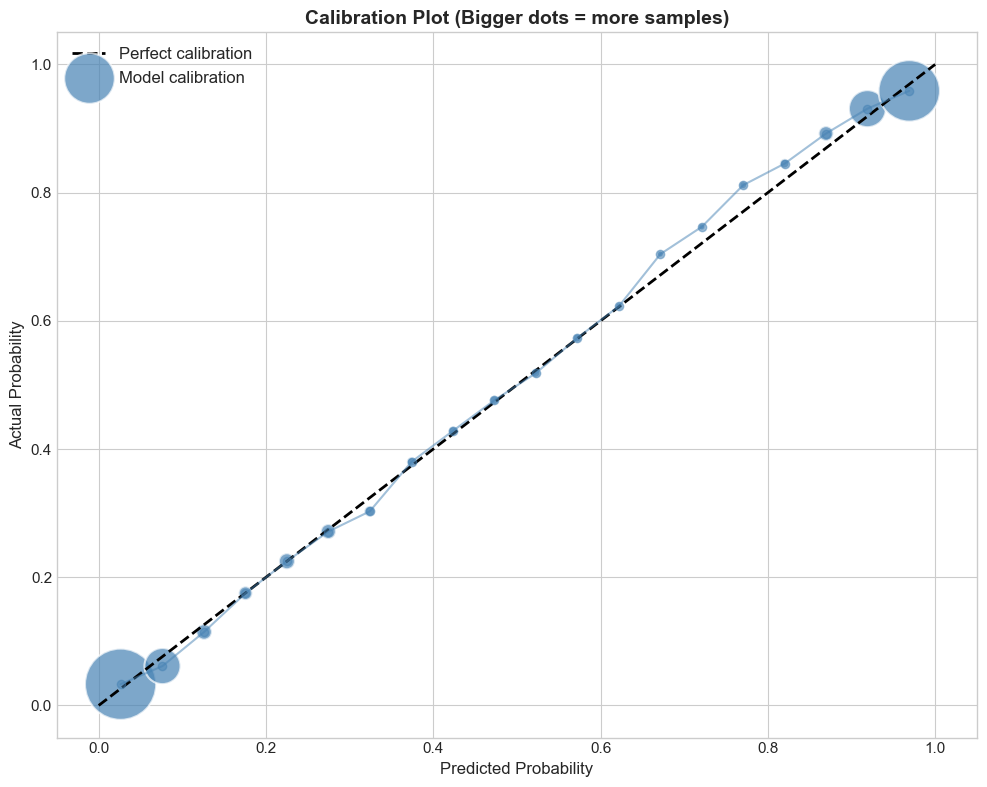

Brier Score: 0.060735 (lower is better)
Log Loss:    0.227148 (lower is better)


In [12]:
from sklearn.metrics import log_loss, brier_score_loss
temp = X_train.copy()
temp['oof_pred'] = oof_lgbm
temp['target'] = y_train
temp['pred_bin'] = pd.cut(temp['oof_pred'], bins=20)
calibration = temp.groupby('pred_bin', observed=True)['target'].agg(['mean', 'count']).reset_index()
calibration['pred_mid'] = calibration['pred_bin'].apply(lambda x: x.mid)

fig, ax = plt.subplots(figsize=(10, 8))

# Perfect calibration line
ax.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Perfect calibration')

# Actual calibration
ax.scatter(calibration['pred_mid'], calibration['mean'],
           s=calibration['count'] / 100, alpha=0.7, color='steelblue',
           edgecolor='white', linewidth=1.5, label='Model calibration')
ax.plot(calibration['pred_mid'], calibration['mean'], 'o-', color='steelblue', alpha=0.5)

ax.set_xlabel('Predicted Probability', fontsize=12)
ax.set_ylabel('Actual Probability', fontsize=12)
ax.set_title('Calibration Plot (Bigger dots = more samples)', fontweight='bold', fontsize=14)
ax.legend(fontsize=12)
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.show()

brier = brier_score_loss(y_train, oof_lgbm)
logloss = log_loss(y_train, oof_lgbm)
print(f'Brier Score: {brier:.6f} (lower is better)')
print(f'Log Loss:    {logloss:.6f} (lower is better)')

In [ ]:
lgb_oof, lgb_test = seed_average(train_cv_lgbm, X_train, y_train, X_test, FEATURES, lgb_params, seeds, do_TE=False, TE_COLS=TE_COLS)

In [ ]:
xgb_oof, xgb_test = seed_average(train_cv_xgb, X_train, y_train, X_test, FEATURES, xgb_params, seeds, do_TE=True, TE_COLS=TE_COLS)

In [ ]:
xgb_oof, xgb_test = seed_average(train_cv_xgb, X_train, y_train, X_test, FEATURES, xgb_params, seeds, do_TE=False, TE_COLS=TE_COLS)

In [ ]:
cat_oof, cat_test = seed_average(train_cv_catboost, X_train, y_train, X_test, FEATURES, cat_params, seeds, do_TE=False, TE_COLS=TE_COLS)

In [ ]:
tabm_oof, tabm_test = seed_average(train_cv_tabm, X_train, y_train, X_test, FEATURES, tabm_params, seeds, do_TE=False, TE_COLS=TE_COLS)

In [ ]:
mlp_oof, mlp_test = seed_average(train_cv_mlp, X_train, y_train, X_test, FEATURES, realmlp_params, seeds, do_TE=False, TE_COLS=TE_COLS)

In [ ]:
oof_dict = {'lgbm': lgb_oof, 'xgb': xgb_oof, 'catboost': cat_oof, 'tabm': tabm_oof, 'mlp': mlp_oof}
test_dict = {'lgbm': lgb_test, 'xgb': xgb_test, 'catboost': cat_test, 'tabm': tabm_test, 'mlp': mlp_test}

final_oof, final_test, final_weights = rank_blend(oof_dict, test_dict, y_train)

submission = pd.DataFrame({
    'id': test['id'],
    'satisfaction': final_test
})
submission.to_csv('submission_blend_rank_opt.csv', index=False)
print('Saved ranked ensemble submission: submission_blend_rank_opt.csv')
print(f'Final CV AUC: {roc_auc_score(y_train, final_oof):.6f}')

oof_save = pd.DataFrame(oof_dict)
oof_save['target'] = y_train
oof_save.to_csv('oof_predictions_v1.csv', index=False)

test_oof_save = pd.DataFrame(test_dict)
test_oof_save.to_csv('test_oof_predictions_v1.csv', index=False)